In [69]:
from datasets import load_dataset
import nltk
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
import pandas as pd
import seaborn as sns

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/ninahew/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [113]:
# Write a function that takes an integer x and two languages, and returns shared word analysis across x number of wikipedia articles


def shared_word_analysis(x, lang_1, lang_2):
    lang_1_ds = load_dataset("wikimedia/wikipedia", "20231101.{lang_1}".format(lang_1=lang_1))
    lang_2_ds = load_dataset("wikimedia/wikipedia", "20231101.{lang_2}".format(lang_2=lang_2))
    print('datasets loaded')
    # Consider returning number of rows in datasets
    corpus_lang_1 = lang_1_ds['train']['text'][0:x]
    corpus_lang_2 = lang_2_ds['train']['text'][0:x]
    # print(corpus_lang_1)
    # Convert to big string
    string_lang_1 = " ".join(corpus_lang_1)
    string_lang_2 = " ".join(corpus_lang_2)
    tokenized_lang_1= word_tokenize(string_lang_1)
    print("After tokenisation")
    print("{lang_1}".format(lang_1=lang_1), ":", str(len(tokenized_lang_1)), "words")
    tokenized_lang_2= word_tokenize(string_lang_2)
    print("{lang_2}".format(lang_2=lang_2), ":", str(len(tokenized_lang_2)), "words")
    # Remove punctuation, proper nouns and numerical entries
    cleaned_lang1 = [word for word in tokenized_lang_1 if ((len(word) > 2) and (not(word[0].isupper())) and (not(word.isnumeric())))]
    print("After data cleaning")
    print("{lang_1}".format(lang_1=lang_1), ":", str(len(cleaned_lang1)), "words")
    cleaned_lang2 = [word for word in tokenized_lang_2 if ((len(word) > 2) and (not(word[0].isupper())) and (not(word.isnumeric())))]
    print("{lang_2}".format(lang_2=lang_2), ":", str(len(cleaned_lang2)), "words")
    dict_lang_1 = {}
    dict_lang_2 = {}
    for word in cleaned_lang1:
        if word not in dict_lang_1:
            dict_lang_1[word] = 0
        dict_lang_1[word] += 1
    for word in cleaned_lang2:
        if word not in dict_lang_2:
            dict_lang_2[word] = 0
        dict_lang_2[word] += 1
    lang_1_df = pd.DataFrame.from_dict(dict_lang_1, orient='index', columns=['word_freq_{lang_1}'.format(lang_1=lang_1)])
    print(lang_1_df.sort_values(by = ['word_freq_{lang_1}'.format(lang_1=lang_1)], ascending= False).head(10))
    lang_2_df = pd.DataFrame.from_dict(dict_lang_2, orient='index', columns = ['word_freq_{lang_2}'.format(lang_2=lang_2)])
    print(lang_2_df.sort_values(by = ['word_freq_{lang_2}'.format(lang_2=lang_2)], ascending= False).head(10))
    shared_words = pd.merge(lang_1_df, lang_2_df, how = 'inner', left_index=True, right_index=True)
    print(str(shared_words.size), "words shared between both languages")
    sns.set_theme(rc={'figure.figsize':(15,10)})
    sns.set_theme(style="darkgrid", context="paper")
    sns.color_palette("Spectral", as_cmap=True)
    compare_plot = sns.lineplot(data = shared_words, sort = True)
    compare_plot.set_xticklabels(compare_plot.get_xticklabels(), rotation=90)
    return compare_plot



datasets loaded
After tokenisation
af : 9080 words
nl : 29975 words
After data cleaning
af : 4430 words
nl : 15502 words
          word_freq_af
die                639
van                345
wat                 76
word                62
het                 57
nie                 37
deur                35
met                 35
grootste            33
dit                 31
      word_freq_nl
van           1065
het            705
een            512
zijn           245
met            219
werd           168
voor           166
die            157
door           145
aan            141
476 words shared between both languages


/var/folders/l6/s5gyjbdn5p738r05bp2xk7300000gn/T/ipykernel_22643/3114277535.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  compare_plot.set_xticklabels(compare_plot.get_xticklabels(), rotation=90)


Axes(0.125,0.11;0.775x0.77)


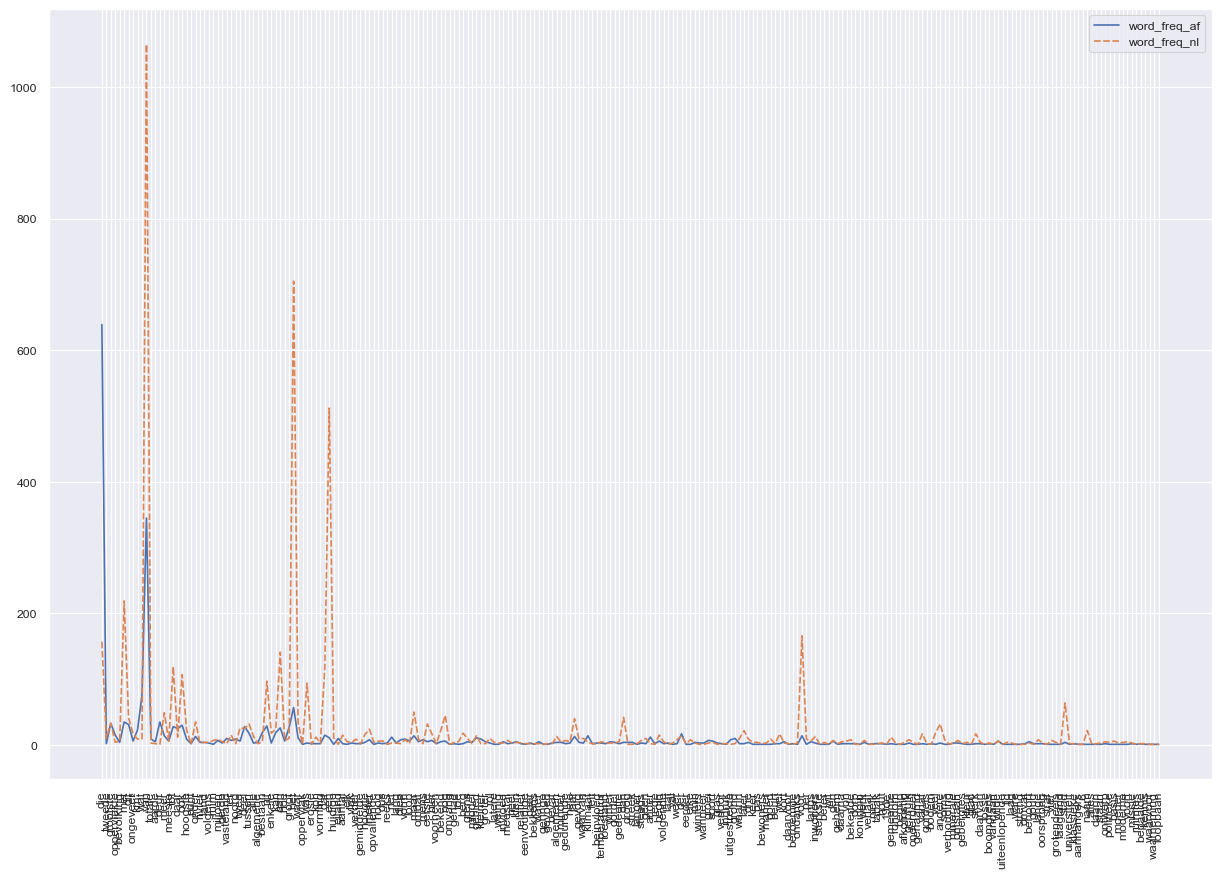

In [114]:
print(shared_word_analysis(10, 'af','nl'))